In [ ]:
pip install numpy pandas matplotlib scikit-learn scipy shap joblib openpyxl


Reading Dataset...
Dataset Shape: (943957, 24)
Training Samples: 660769 | Testing Samples: 283188

Training Random Forest...
Training Completed.

RANDOM FOREST MODEL PERFORMANCE SUMMARY
Train R² : 0.8189
Test R²  : 0.7945
Train RMSE: 0.1147
Test RMSE : 0.1223
Train MAE : 0.0840
Test MAE  : 0.0897

Generating Dark Points Scatter Plots...


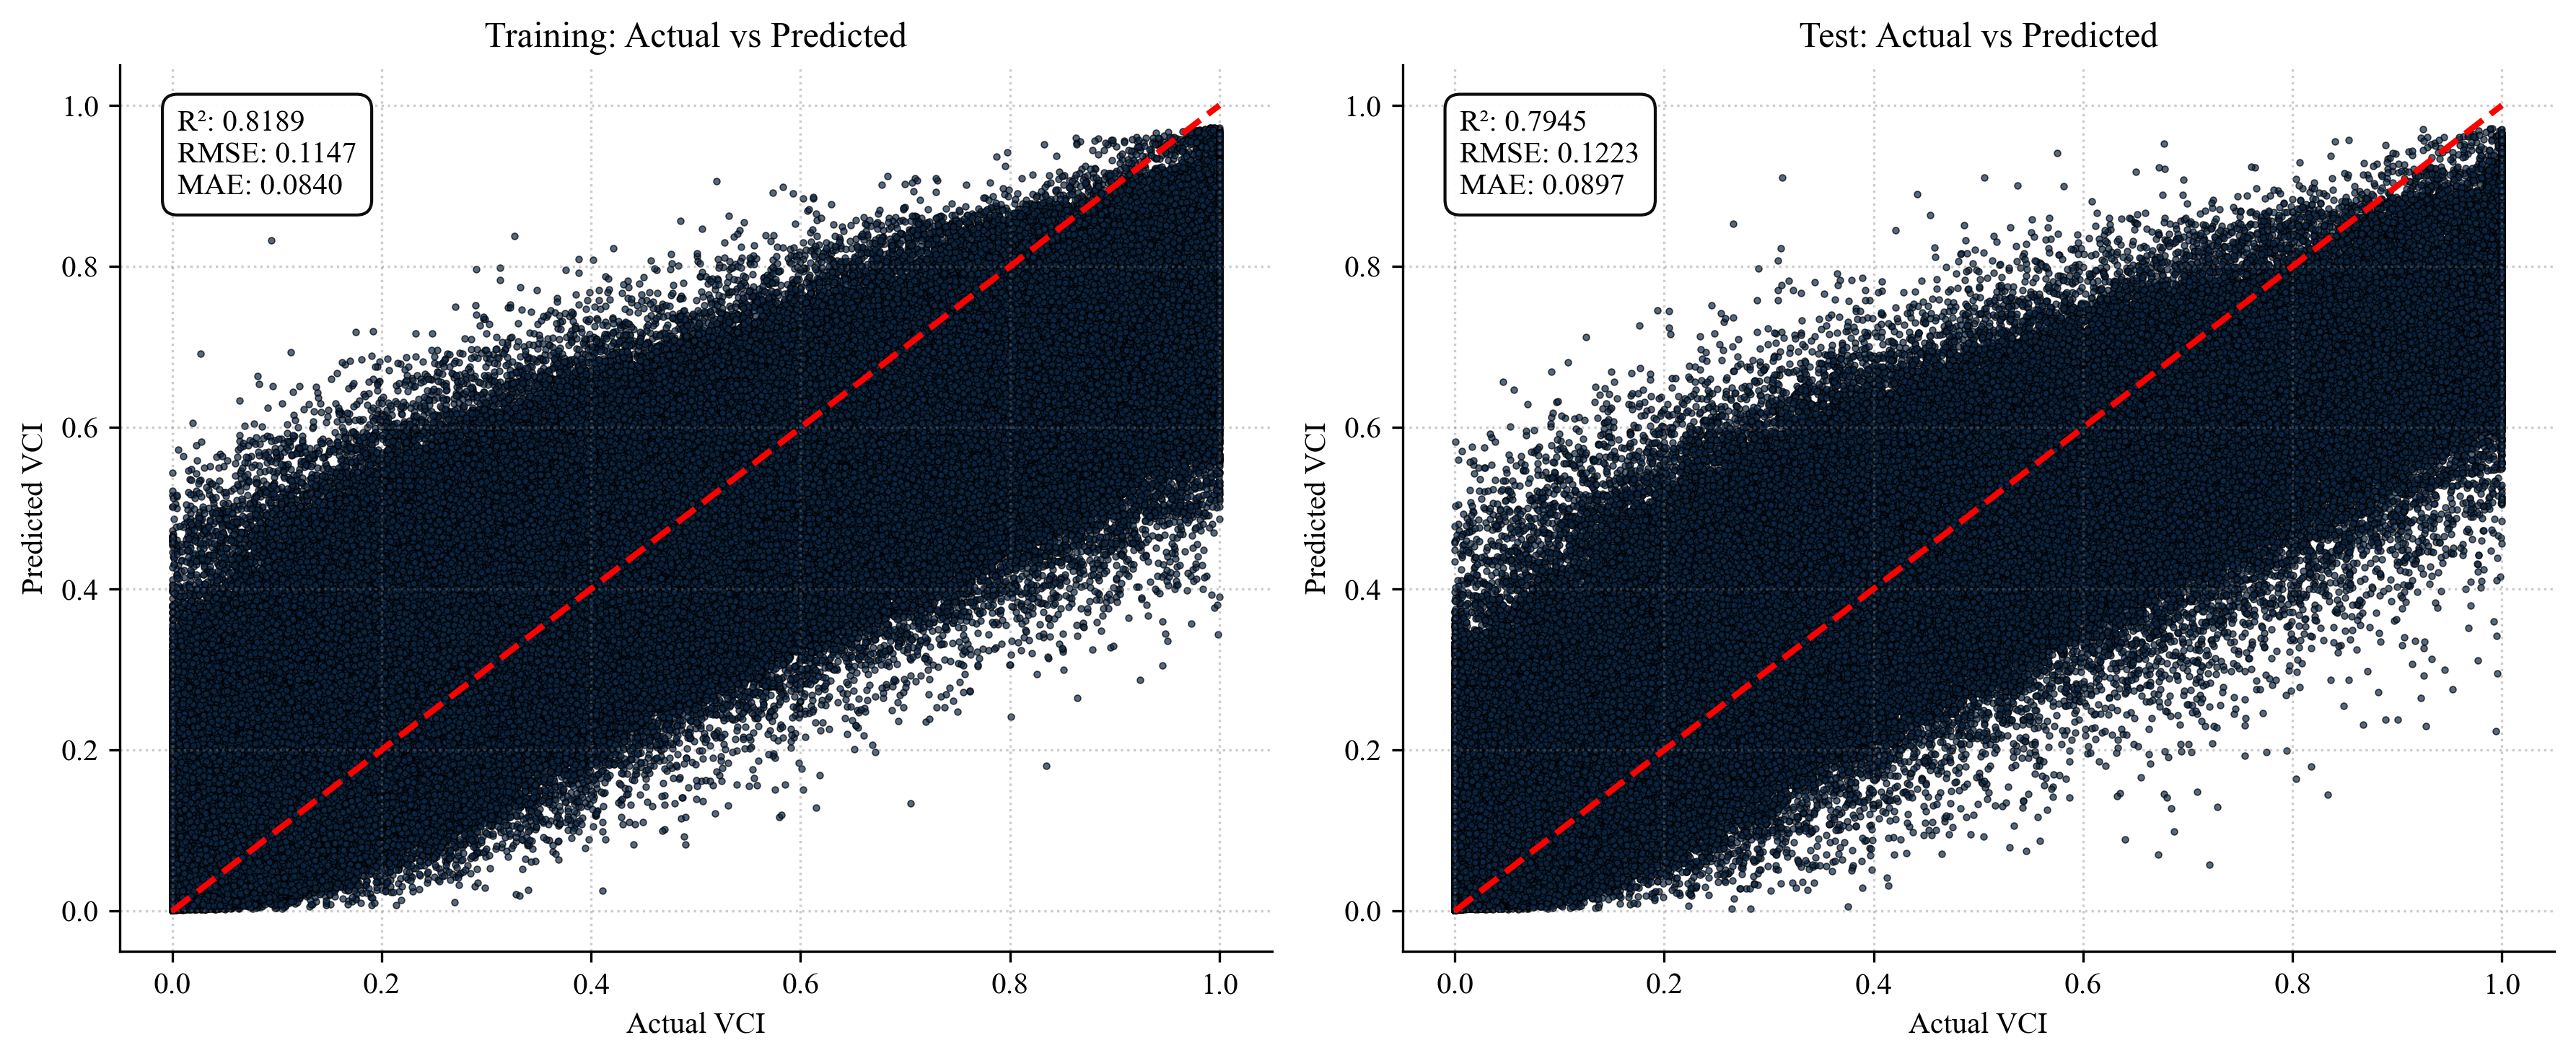


✅ Plot saved successfully as: RF_Journal_DarkPoints_RedLine.png


In [13]:
# ======================================================================
# Random Forest Regressor - Dark Points + Red Diagonal Line
# ======================================================================
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor

# ======================================================================
# REPRODUCIBILITY & PATHS
# ======================================================================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

output_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\RF_Output"
os.makedirs(output_dir, exist_ok=True)

ml_dir = r"E:\2_Contribution\Final\Preprocess\1_ML\XGboost_Output"
input_csv = os.path.join(ml_dir, "lagged_ml_ready.csv")

# ======================================================================
# READ DATASET
# ======================================================================
print("\nReading Dataset...")
df = pd.read_csv(input_csv)
print(f"Dataset Shape: {df.shape}")

# ======================================================================
# FEATURES & TARGET
# ======================================================================
drop_columns = ["VCI", "Row_Idx", "Col_Idx", "Year"]
X = df.drop(columns=drop_columns)
y = df["VCI"].copy()

target_scaler = MinMaxScaler()
y = target_scaler.fit_transform(y.values.reshape(-1, 1)).ravel()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, shuffle=True
)
print(f"Training Samples: {len(X_train)} | Testing Samples: {len(X_test)}")

# ======================================================================
# TRAIN MODEL
# ======================================================================
print("\nTraining Random Forest...")
rf_model = RandomForestRegressor(
    n_estimators=600,
    max_depth=15,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features='sqrt',
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
print("Training Completed.")

# ======================================================================
# PERFORMANCE
# ======================================================================
def evaluate_model(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred)
    }

train_metrics = evaluate_model(y_train, rf_model.predict(X_train))
test_metrics = evaluate_model(y_test, rf_model.predict(X_test))

print("\n" + "="*70)
print("RANDOM FOREST MODEL PERFORMANCE SUMMARY")
print("="*70)
print(f"Train R² : {train_metrics['R2']:.4f}")
print(f"Test R²  : {test_metrics['R2']:.4f}")
print(f"Train RMSE: {train_metrics['RMSE']:.4f}")
print(f"Test RMSE : {test_metrics['RMSE']:.4f}")
print(f"Train MAE : {train_metrics['MAE']:.4f}")
print(f"Test MAE  : {test_metrics['MAE']:.4f}")
print("="*70)

# ======================================================================
# CLEAN JOURNAL SCATTER PLOTS (Dark Points + Red Diagonal)
# ======================================================================
print("\nGenerating Dark Points Scatter Plots...")

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["figure.dpi"] = 300

fig = plt.figure(figsize=(12, 5), facecolor='white')
box_props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.95, edgecolor='black')

point_color = '#0d2a4a'   # Dark blue (almost dark)

# --- Training Plot ---
ax1 = plt.subplot(1, 2, 1, facecolor='white')
ax1.scatter(y_train, rf_model.predict(X_train),
            alpha=0.7,
            color=point_color,
            edgecolor='black',
            s=4.5,
            linewidth=0.4)

# Red diagonal line
ax1.plot([0, 1], [0, 1], 'r--', lw=2.0)

train_text = f"R²: {train_metrics['R2']:.4f}\nRMSE: {train_metrics['RMSE']:.4f}\nMAE: {train_metrics['MAE']:.4f}"
ax1.text(0.05, 0.95, train_text, transform=ax1.transAxes, fontsize=10,
         verticalalignment='top', bbox=box_props)

ax1.set_xlim([-0.05, 1.05])
ax1.set_ylim([-0.05, 1.05])
ax1.set_xlabel('Actual VCI')
ax1.set_ylabel('Predicted VCI')
ax1.set_title('Training: Actual vs Predicted')

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_linewidth(0.8)
ax1.spines['bottom'].set_linewidth(0.8)
ax1.grid(True, linestyle=':', alpha=0.4, color='gray')

# --- Test Plot ---
ax2 = plt.subplot(1, 2, 2, facecolor='white')
ax2.scatter(y_test, rf_model.predict(X_test),
            alpha=0.7,
            color=point_color,
            edgecolor='black',
            s=4.5,
            linewidth=0.4)

# Red diagonal line
ax2.plot([0, 1], [0, 1], 'r--', lw=2.0)

test_text = f"R²: {test_metrics['R2']:.4f}\nRMSE: {test_metrics['RMSE']:.4f}\nMAE: {test_metrics['MAE']:.4f}"
ax2.text(0.05, 0.95, test_text, transform=ax2.transAxes, fontsize=10,
         verticalalignment='top', bbox=box_props)

ax2.set_xlim([-0.05, 1.05])
ax2.set_ylim([-0.05, 1.05])
ax2.set_xlabel('Actual VCI')
ax2.set_ylabel('Predicted VCI')
ax2.set_title('Test: Actual vs Predicted')

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_linewidth(0.8)
ax2.spines['bottom'].set_linewidth(0.8)
ax2.grid(True, linestyle=':', alpha=0.4, color='gray')

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "RF_Journal_DarkPoints_RedLine.png"),
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"\n✅ Plot saved successfully as: RF_Journal_DarkPoints_RedLine.png")

In [8]:
# =====================================================================
# PART 2: OPTIMIZED RANDOM FOREST WITH FIXED PARAMETERS
# =====================================================================
print("\n" + "=" * 70)
print("RANDOM FOREST REGRESSION - PART 2")
print("=" * 70)

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score
import numpy as np

# =====================================================================
# STEP 11: DEFINE IMPROVED FIXED MODEL
# =====================================================================
print("\nStep 11: Initializing Improved Random Forest...")

rf_model = RandomForestRegressor(
    n_estimators=800,           # Increased
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt',        # ← Changed to 'sqrt' (safest)
    # max_features=0.7,         # Alternative: use float like 0.7 if your sklearn version supports it
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model initialized with improved parameters.")

# =====================================================================
# STEP 12: TRAIN THE MODEL
# =====================================================================
print("\nStep 12: Training Optimized Random Forest...")
rf_model.fit(X_train, y_train)
print("✅ Model trained successfully.")

# =====================================================================
# STEP 13: 5-FOLD CROSS VALIDATION
# =====================================================================
print("\nStep 13: Performing 5-Fold Cross Validation...")

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="r2",
    n_jobs=-1
)

print("\nCross Validation Scores (R²)")
print("-" * 50)
for i, score in enumerate(cv_scores):
    print(f"Fold {i+1}: {score:.4f}")

print("-" * 50)
print(f"Mean CV R² : {cv_scores.mean():.4f}")
print(f"Std CV R²  : {cv_scores.std():.4f}")

# =====================================================================
# FINAL SUMMARY
# =====================================================================
print("\n" + "="*70)
print("PART 2 COMPLETED SUCCESSFULLY")
print("="*70)
print(f"Mean CV R² : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print("="*70)


RANDOM FOREST REGRESSION - PART 2

Step 11: Initializing Improved Random Forest...
Random Forest model initialized with improved parameters.

Step 12: Training Optimized Random Forest...
✅ Model trained successfully.

Step 13: Performing 5-Fold Cross Validation...

Cross Validation Scores (R²)
--------------------------------------------------
Fold 1: 0.7105
Fold 2: 0.7173
Fold 3: 0.7052
Fold 4: 0.7111
Fold 5: 0.7092
--------------------------------------------------
Mean CV R² : 0.7107
Std CV R²  : 0.0039

PART 2 COMPLETED SUCCESSFULLY
Mean CV R² : 0.7107 ± 0.0039
